<a href="https://colab.research.google.com/github/kzlnyi/ML/blob/main/%22%D0%9B%D0%A0_10_%D0%9C%D0%9D_%D0%9A%D0%B5%D1%80%D0%B0%D1%81_%D0%93%D0%BE%D0%BB%D0%BE%D0%B2%D0%B5%D0%BD%D0%BA%D0%BE_%D0%A4%D0%86%D0%A2_3_12_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** Головенко Костянтин
**Група:** ФІТ 3-12
**Дата:** 27.11.2026

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [18]:
# Підготуйте імпорти TensorFlow / Keras, NumPy, Matplotlib,
# classification_report, а також потрібних callback-функцій.
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [19]:
# Завантажте Fashion MNIST, визначте class_names.
# Виведіть форми x_train, y_train, x_test, y_test.
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

print("x_train:", x_train.shape)
print("y_train:", y_train.shape)
print("x_test: ", x_test.shape)
print("y_test: ", y_test.shape)

x_train: (60000, 28, 28)
y_train: (60000,)
x_test:  (10000, 28, 28)
y_test:  (10000,)


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

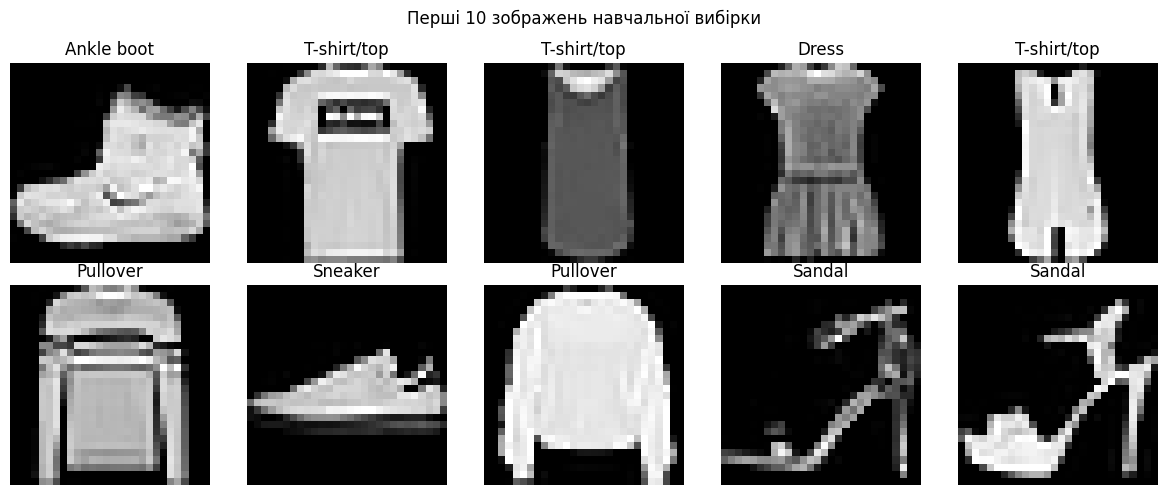

In [20]:
# Побудуйте візуалізацію 10 зображень із підписами класів.
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(class_names[y_train[i]])
    plt.axis('off')
plt.suptitle("Перші 10 зображень навчальної вибірки")
plt.tight_layout()
plt.show()

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [22]:
# Нормалізуйте навчальні й тестові дані.
# Перевірте діапазони значень.
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

print("Тип даних:", x_train.dtype)
print("Діапазон x_train: [%.1f; %.1f]" % (x_train.min(), x_train.max()))
print("Діапазон x_test:  [%.1f; %.1f]" % (x_test.min(), x_test.max()))

Тип даних: float32
Діапазон x_train: [0.0; 1.0]
Діапазон x_test:  [0.0; 1.0]


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [23]:
# Створіть і скомпілюйте модель.
model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

256 і 128 нейронів достатньо, щоб вивчити ознаки з 784 пікселів, але модель не надто велика і не перенавчається; зменшення кількості нейронів (256 -> 128) поступово стискає ознаки.
Dropout 0.3: під час навчання вимикає 30% нейронів, це зменшує перенавчання;Швидкість навчання 0.001: стандартне стабільне значення для Adam;
ReduceLROnPlateau зменшує її, коли val_loss перестає падати.

### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [24]:
# Налаштуйте callbacks і навчіть модель.
# Збережіть history.
# Валідаційна частина виділяється з навчальних даних (тест не чіпаємо)
x_tr, x_val, y_tr, y_val = train_test_split(
    x_train, y_train, test_size=0.2, random_state=SEED, stratify=y_train
)
print("Train:", x_tr.shape, "| Val:", x_val.shape)

def get_callbacks():
    return [
        EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1)
    ]

history = model.fit(
    x_tr, y_tr,
    validation_data=(x_val, y_val),
    epochs=50,
    batch_size=128,
    callbacks=get_callbacks(),
    verbose=2
)

epochs_task1 = len(history.history['loss'])
print("Кількість епох навчання:", epochs_task1)

Train: (48000, 28, 28) | Val: (12000, 28, 28)
Epoch 1/50
375/375 - 7s - 20ms/step - accuracy: 0.7635 - loss: 0.6616 - val_accuracy: 0.8474 - val_loss: 0.4177 - learning_rate: 0.0010
Epoch 2/50
375/375 - 4s - 12ms/step - accuracy: 0.8353 - loss: 0.4525 - val_accuracy: 0.8634 - val_loss: 0.3706 - learning_rate: 0.0010
Epoch 3/50
375/375 - 4s - 9ms/step - accuracy: 0.8516 - loss: 0.4081 - val_accuracy: 0.8720 - val_loss: 0.3530 - learning_rate: 0.0010
Epoch 4/50
375/375 - 3s - 9ms/step - accuracy: 0.8607 - loss: 0.3812 - val_accuracy: 0.8752 - val_loss: 0.3405 - learning_rate: 0.0010
Epoch 5/50
375/375 - 3s - 7ms/step - accuracy: 0.8662 - loss: 0.3645 - val_accuracy: 0.8783 - val_loss: 0.3307 - learning_rate: 0.0010
Epoch 6/50
375/375 - 4s - 12ms/step - accuracy: 0.8707 - loss: 0.3507 - val_accuracy: 0.8838 - val_loss: 0.3216 - learning_rate: 0.0010
Epoch 7/50
375/375 - 3s - 8ms/step - accuracy: 0.8746 - loss: 0.3376 - val_accuracy: 0.8831 - val_loss: 0.3224 - learning_rate: 0.0010
Epoch 

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [25]:
# Виведіть підсумок архітектури моделі.
model.summary()
print("Кількість шарів:", len(model.layers))
print("Кількість параметрів:", model.count_params())

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)

Кількість шарів: 6
Кількість параметрів: 235146


### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [28]:
# Збережіть навчену модель (.keras).
# За потреби підключіть Google Drive.
model_path = 'fashion_mnist_model.keras'
model.save(model_path)
print("Модель збережено:", model_path)

Модель збережено: fashion_mnist_model.keras


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

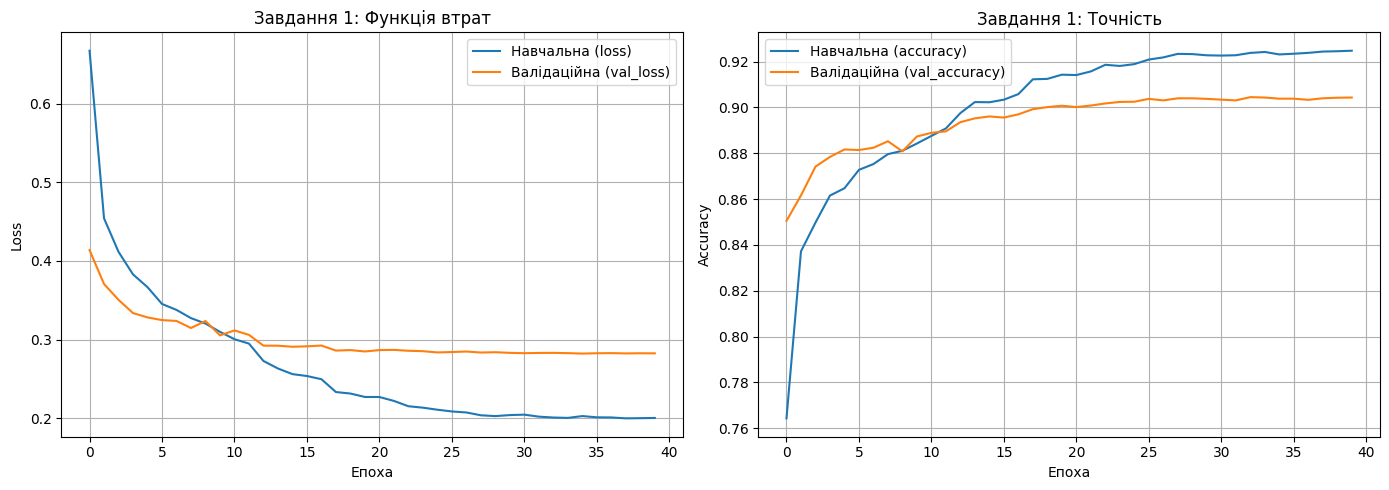

In [9]:
# Побудуйте графіки loss/val_loss та accuracy/val_accuracy.
def plot_history(history, title_prefix=""):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(history.history['loss'], label='Навчальна (loss)')
    axes[0].plot(history.history['val_loss'], label='Валідаційна (val_loss)')
    axes[0].set_title(f'{title_prefix}Функція втрат')
    axes[0].set_xlabel('Епоха')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(history.history['accuracy'], label='Навчальна (accuracy)')
    axes[1].plot(history.history['val_accuracy'], label='Валідаційна (val_accuracy)')
    axes[1].set_title(f'{title_prefix}Точність')
    axes[1].set_xlabel('Епоха')
    axes[1].set_ylabel('Accuracy')
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

plot_history(history, "Завдання 1: ")

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [29]:
# Обчисліть loss і accuracy на тестовій вибірці.
# Знайдіть прогнозовані класи та сформуйте classification_report.
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")
print("Поріг 0.87 досягнуто:", "ТАК" if test_acc >= 0.87 else "НІ")

y_pred = np.argmax(model.predict(x_test, verbose=0), axis=1)

print("\nКласифікаційний звіт:\n")
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

Test loss: 0.3138
Test accuracy: 0.8931
Поріг 0.87 досягнуто: ТАК

Класифікаційний звіт:

              precision    recall  f1-score   support

 T-shirt/top     0.8408    0.8610    0.8508      1000
     Trouser     0.9939    0.9730    0.9833      1000
    Pullover     0.7959    0.8110    0.8034      1000
       Dress     0.8925    0.9050    0.8987      1000
        Coat     0.7998    0.8230    0.8112      1000
      Sandal     0.9778    0.9700    0.9739      1000
       Shirt     0.7335    0.6880    0.7100      1000
     Sneaker     0.9481    0.9680    0.9579      1000
         Bag     0.9809    0.9750    0.9779      1000
  Ankle boot     0.9667    0.9570    0.9618      1000

    accuracy                         0.8931     10000
   macro avg     0.8930    0.8931    0.8929     10000
weighted avg     0.8930    0.8931    0.8929     10000



### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

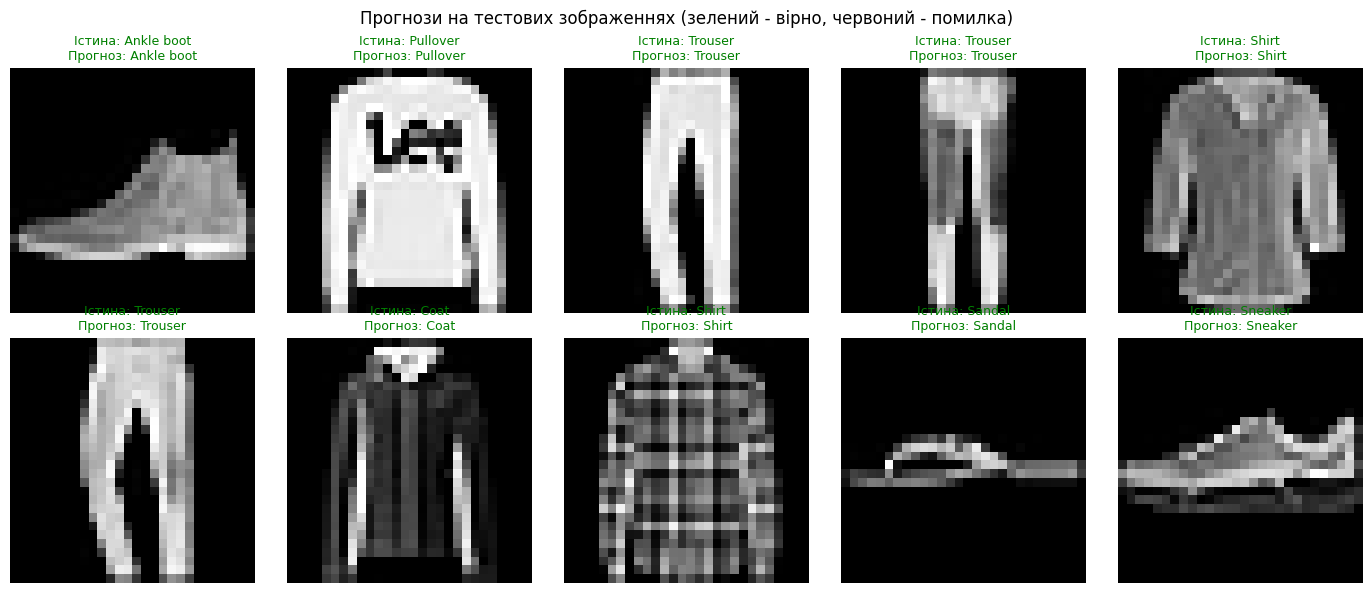

In [30]:
# Візуалізуйте 10 зображень: справжні й прогнозовані класи.
plt.figure(figsize=(14, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    true_label = class_names[y_test[i]]
    pred_label = class_names[y_pred[i]]
    color = 'green' if y_test[i] == y_pred[i] else 'red'
    plt.title(f"Істина: {true_label}\nПрогноз: {pred_label}", color=color, fontsize=9)
    plt.axis('off')
plt.suptitle("Прогнози на тестових зображеннях (зелений - вірно, червоний - помилка)")
plt.tight_layout()
plt.show()

**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

**Ваш висновок:**  
Тестова accuracy моделі становить 0.8924, а тестові loss - 0.3155. Це більше за поріг 0,87, тому вимогу щодо мінімальної точності виконано. Навчання зупинилося на 40 епосі завдяки EarlyStopping. Точність на навчальній вибірці (0.925) трохи вища за валідаційну (0.904), тобто невелике перенавчання є, але несуттєве.

Найбільше помилок модель робить у класах Shirt (F1 = 0.71), Pullover (0.80) і Coat (0.81). Це візуально схожі речі одягу з довгими рукавами, тому модель плутає їх між собою. Найкраще розпізнаються Trouser (0.98), Bag (0.98) і Sandal (0.97), бо вони мають чітку, характерну форму.

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [31]:
# За потреби встановіть keras-tuner.
# Імпортуйте RandomSearch та потрібні компоненти Keras.
!pip install -q keras-tuner

from keras_tuner import RandomSearch
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.regularizers import l2

### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [32]:
# Підготуйте дані для добору гіперпараметрів і фінального тестування.
# Ваш код:
print("Train:", x_tr.shape, "| Val:", x_val.shape, "| Test (лише для фіналу):", x_test.shape)
print("Діапазон значень: [%.1f; %.1f]" % (x_tr.min(), x_tr.max()))

Train: (48000, 28, 28) | Val: (12000, 28, 28) | Test (лише для фіналу): (10000, 28, 28)
Діапазон значень: [0.0; 1.0]


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [33]:
# Опишіть функцію build_model(hp).
# Задайте області пошуку гіперпараметрів.
def build_model(hp):
    model = keras.Sequential()
    model.add(layers.Input(shape=(28, 28)))
    model.add(Flatten())

    for i in range(hp.Int('num_layers', 1, 3)):
        model.add(Dense(
            units=hp.Int(f'units_{i}', min_value=32, max_value=512, step=32),
            activation='relu',
            kernel_regularizer=l2(1e-4)
        ))
        model.add(Dropout(0.3))

    model.add(Dense(10, activation='softmax'))

    lr = hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [34]:
# Ініціалізуйте RandomSearch.
tuner = RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=3,
    executions_per_trial=1,
    directory='keras_tuner_results',
    project_name='fashion_mnist',
    overwrite=True,
    seed=SEED
)

tuner.search_space_summary()

Search space summary
Default search space size: 3
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [35]:
# Виконайте пошук, отримайте найкращі гіперпараметри і модель.
# Навчіть вибрану модель без використання тестових даних.
tuner.search(
    x_tr, y_tr,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=128,
    callbacks=get_callbacks(),
    verbose=2
)

best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
n_layers = best_hps.get('num_layers')
units_list = [best_hps.get(f'units_{i}') for i in range(n_layers)]
best_lr = best_hps.get('learning_rate')

print("Найкращі гіперпараметри:")
print("  Кількість прихованих шарів:", n_layers)
print("  Кількість нейронів по шарах:", units_list)
print("  Швидкість навчання:", best_lr)

# Перенавчання найкращої конфігурації зі збереженням історії (без тестових даних)
best_model = tuner.hypermodel.build(best_hps)
best_model.summary()

history_best = best_model.fit(
    x_tr, y_tr,
    validation_data=(x_val, y_val),
    epochs=50,
    batch_size=128,
    callbacks=get_callbacks(),
    verbose=2
)
epochs_task2 = len(history_best.history['loss'])
print("Кількість епох навчання:", epochs_task2)

Trial 3 Complete [00h 01m 40s]
val_accuracy: 0.8854166865348816

Best val_accuracy So Far: 0.9039999842643738
Total elapsed time: 00h 04m 57s
Найкращі гіперпараметри:
  Кількість прихованих шарів: 1
  Кількість нейронів по шарах: [480]
  Швидкість навчання: 0.001


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 480)            │       376,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 480)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         4,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 381,610 (1.46 MB)

 Trainable params: 381,610 (1.46 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
375/375 - 6s - 16ms/step - accuracy: 0.7975 - loss: 0.6301 - val_accuracy: 0.8380 - val_loss: 0.4940 - learning_rate: 0.0010
Epoch 2/50
375/375 - 4s - 11ms/step - accuracy: 0.8479 - loss: 0.4748 - val_accuracy: 0.8627 - val_loss: 0.4361 - learning_rate: 0.0010
Epoch 3/50
375/375 - 4s - 11ms/step - accuracy: 0.8614 - loss: 0.4369 - val_accuracy: 0.8664 - val_loss: 0.4227 - learning_rate: 0.0010
Epoch 4/50
375/375 - 6s - 15ms/step - accuracy: 0.8678 - loss: 0.4140 - val_accuracy: 0.8741 - val_loss: 0.4038 - learning_rate: 0.0010
Epoch 5/50
375/375 - 4s - 11ms/step - accuracy: 0.8750 - loss: 0.3986 - val_accuracy: 0.8793 - val_loss: 0.3888 - learning_rate: 0.0010
Epoch 6/50
375/375 - 4s - 10ms/step - accuracy: 0.8771 - loss: 0.3888 - val_accuracy: 0.8803 - val_loss: 0.3844 - learning_rate: 0.0010
Epoch 7/50
375/375 - 5s - 14ms/step - accuracy: 0.8792 - loss: 0.3807 - val_accuracy: 0.8833 - val_loss: 0.3795 - learning_rate: 0.0010
Epoch 8/50
375/375 - 4s - 11ms/step - accuracy: 

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

Test loss: 0.3489
Test accuracy: 0.8968


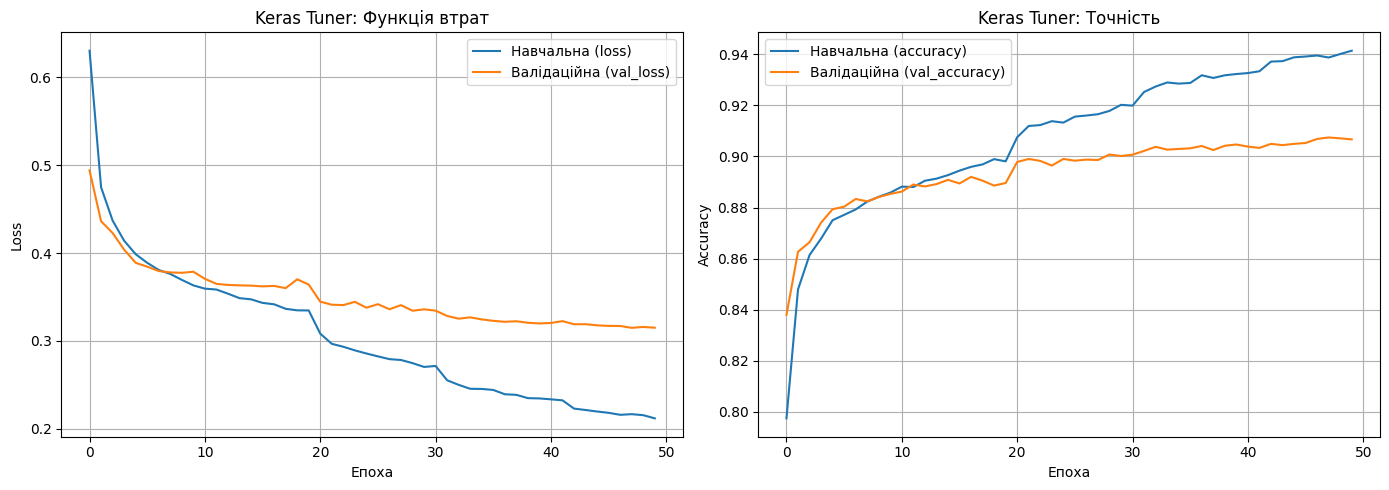

In [36]:
# Оцініть найкращу модель та побудуйте графіки навчання.
best_loss, best_acc = best_model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss: {best_loss:.4f}")
print(f"Test accuracy: {best_acc:.4f}")

plot_history(history_best, "Keras Tuner: ")

# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів | 2 | 1 |
| Кількість нейронів | 256, 128 | 480 |
| Швидкість навчання | 0.001 | 0.001 |
| Точність на тестовій вибірці (accuracy) | 0.8924 | 0.8958 |
| Втрати на тестовій вибірці (loss) | 0.3155 | 0.3428 |
| Кількість епох навчання | 40 | 50 |

**У висновках дайте відповідь:**

1. Чи досягнуто точності **не нижче 0,87** у завданні 1?
2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?
3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?
4. Які класи Fashion MNIST класифікувати найскладніше?

**Власні висновки:**  
**1. Чи досягнуто точності не нижче 0,87 у завданні 1?**
Так, досягнуто. Тестова accuracy становить 0.8924, що вище за поріг 0,87.

**2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?**
Так, але зовсім трохи: з 0.8924 до 0.8958. Loss при цьому став більшим (0.3428 проти 0.3155), бо в моделі з Keras Tuner є L2-регуляризація, а її штраф входить у loss. Покращення маленьке, бо було лише 3 спроби пошуку.

**3. Які гіперпараметри виявилися найкращими і чому результат може відрізнятися між запусками?**
Найкраща конфігурація: 1 прихований шар, 480 нейронів, швидкість навчання 0.001. Результат може змінюватися між запусками, бо ваги ініціалізуються випадково, RandomSearch випадково вибирає параметри, а Dropout і порядок батчів теж випадкові.

**4. Які класи Fashion MNIST класифікувати найскладніше?**
Найважче розпізнаються Shirt, Pullover і Coat, бо вони схожі між собою. Найлегше - Trouser, Bag і взуття (Sandal, Sneaker, Ankle boot).

**Загальний висновок:** у роботі я навчився готувати дані Fashion MNIST, будувати й навчати нейромережу в Keras та підбирати гіперпараметри через Keras Tuner. Обидві моделі показали точність понад 0,87, а підбір параметрів дав лише невелике покращення. Тестову вибірку я використовував тільки для фінальної оцінки.

---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.